In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import Image as IPImage, display
from scipy.io import savemat  # opcional, si aún quieres .mat
import io
from PIL import Image
import os

# =============================================================================
# FUNCIONES AUXILIARES
# =============================================================================
def Rot(theta):
    c = np.cos(theta)
    s = np.sin(theta)
    return np.array([[c, -s], [s, c]])

def ecuaciones(q, t, r1, r2, r3, r4, phi20, omega20, alpha20):
    Fq = np.zeros(12)
    Fq[0] = q[0] - np.cos(q[2])*r1/2 - q[3] + np.cos(q[5])*r2/2
    Fq[1] = q[1] - np.sin(q[2])*r1/2 - q[4] + np.sin(q[5])*r2/2
    Fq[2] = q[3] + np.cos(q[5])*r2/2 - q[6] + np.cos(q[8])*r3/2
    Fq[3] = q[4] + np.sin(q[5])*r2/2 - q[7] + np.sin(q[8])*r3/2
    Fq[4] = q[6] - q[9] - np.cos(q[11])*r4/2
    Fq[5] = q[7] - q[10] - np.sin(q[11])*r4/2
    Fq[6] = q[0] + np.cos(q[2])*r1/2 - q[9] + np.cos(q[11])*r4/2
    Fq[7] = q[1] + np.sin(q[2])*r1/2 - q[10] + np.sin(q[11])*r4/2
    Fq[8] = q[0] - r1/2
    Fq[9] = q[1]
    Fq[10] = q[2]
    Fq[11] = q[5] - 0.5*alpha20*t**2 - omega20*t - phi20

    J = np.zeros((12, 12))
    J[0, 0] = 1;  J[0, 2] =  np.sin(q[2])*r1/2;  J[0, 3] = -1;  J[0, 5] = -np.sin(q[5])*r2/2
    J[1, 1] = 1;  J[1, 2] = -np.cos(q[2])*r1/2;  J[1, 4] = -1;  J[1, 5] =  np.cos(q[5])*r2/2
    J[2, 3] = 1;  J[2, 5] = -np.sin(q[5])*r2/2;  J[2, 6] = -1;  J[2, 8] = -np.sin(q[8])*r3/2
    J[3, 4] = 1;  J[3, 5] =  np.cos(q[5])*r2/2;  J[3, 7] = -1;  J[3, 8] =  np.cos(q[8])*r3/2
    J[4, 6] = 1;  J[4, 9] = -1;                  J[4,11] =  np.sin(q[11])*r4/2
    J[5, 7] = 1;  J[5,10] = -1;                  J[5,11] = -np.cos(q[11])*r4/2
    J[6, 0] = 1;  J[6, 2] = -np.sin(q[2])*r1/2;  J[6, 9] = -1;  J[6,11] = -np.sin(q[11])*r4/2
    J[7, 1] = 1;  J[7, 2] =  np.cos(q[2])*r1/2;  J[7,10] = -1;  J[7,11] =  np.cos(q[11])*r4/2
    J[8, 0] = 1
    J[9, 1] = 1
    J[10,2] = 1
    J[11,5] = 1
    return Fq, J

def jacobian_punto(q, v, r1, r2, r3, r4):
    Jp = np.zeros((12, 12))
    Jp[0, 2] =  v[2]*np.cos(q[2])*r1/2;  Jp[0, 5] = -v[5]*np.cos(q[5])*r2/2
    Jp[1, 2] =  v[2]*np.sin(q[2])*r1/2;  Jp[1, 5] = -v[5]*np.sin(q[5])*r2/2
    Jp[2, 5] = -v[5]*np.cos(q[5])*r2/2;  Jp[2, 8] = -v[8]*np.cos(q[8])*r3/2
    Jp[3, 5] = -v[5]*np.sin(q[5])*r2/2;  Jp[3, 8] = -v[8]*np.sin(q[8])*r3/2
    Jp[4, 8] = -v[8]*np.cos(q[8])*r3/2;  Jp[4,11] =  v[11]*np.cos(q[11])*r4/2
    Jp[5, 8] = -v[8]*np.sin(q[8])*r3/2;  Jp[5,11] =  v[11]*np.sin(q[11])*r4/2
    Jp[6, 2] = -v[2]*np.cos(q[2])*r1/2;  Jp[6,11] = -v[11]*np.cos(q[11])*r4/2
    Jp[7, 2] = -v[2]*np.sin(q[2])*r1/2;  Jp[7,11] = -v[11]*np.sin(q[11])*r4/2
    return Jp

In [6]:
# =============================================================================
# PARÁMETROS DEL MECANISMO
# =============================================================================
r1 = 0.1; r2 = 0.05; r3 = 0.25; r4 = 0.125
phi20 = 2.5
omega20 = np.deg2rad(10)
alpha20 = 0.0

M1 = 1.0; M2 = 1.0; M3 = 1.0; M4 = 1.0
g = 0.0

I1 = 1/12 * M1 * r1**2
I2 = 1/12 * M2 * r2**2
I3 = 1/12 * M3 * r3**2
I4 = 1/12 * M4 * r4**2

Mmat = np.diag([M1, M1, I1, M2, M2, I2, M3, M3, I3, M4, M4, I4])
Fext = np.array([0, -M1*g, 0, 0, -M2*g, 0, 0, -M3*g, 0, 0, -M4*g, 0])

q0 = np.array([0.05, 0.0, 0.0, -0.020, 0.015, 2.5,
               0.051, 0.115, 0.750, 0.076, 0.058, 1.970])

k  = 45.0      # N/m
L0 = 0.1129    # m

# =============================================================================
# FASE 1 – EQUILIBRIO INICIAL
# =============================================================================
q = q0.copy()
t = 0.0
tol = 100.0
iter_ = 0
while tol > 1e-7 and iter_ < 100:
    iter_ += 1
    Fq, J = ecuaciones(q, t, r1, r2, r3, r4, phi20, omega20, alpha20)
    delta_q = np.linalg.solve(J, -Fq)
    q += delta_q
    tol = np.linalg.norm(Fq, 2)
q_foto = q.copy()

# Resortes de torsión
ktO2 = 0.05
KtA  = 0.09
ktB  = 0.09
kt4  = 0.1

theta_eq_O2 = q_foto[5]
theta_eq_A  = q_foto[8] - q_foto[5]
theta_eq_B  = q_foto[8] - q_foto[11]
theta_eq_O4 = q_foto[11]

# Puntos de anclaje del resorte lineal
poi = np.array([-0.0523, -0.0060])
sep = np.array([0.0005, 0.0])

G2_0 = np.array([q[3], q[4]])
G4_0 = np.array([q[9], q[10]])

Ps2_0 = poi + sep
Ps4_0 = poi - sep

poi_r2_local = Rot(q[5]).T @ (Ps2_0 - G2_0)
poi_r4_local = Rot(q[11]).T @ (Ps4_0 - G4_0)

print(f'Distancia inicial entre anclajes: {np.linalg.norm(Ps4_0 - Ps2_0):.5f} m  (L0 = {L0:.5f} m)')

Distancia inicial entre anclajes: 0.00100 m  (L0 = 0.11290 m)


In [7]:
# =============================================================================
# FASE 2 – SIMULACIÓN COMPLETA
# =============================================================================
dt_plot = 0.1
t_final = 36.0
N = int(t_final / dt_plot) + 1   # 361 pasos
time = np.linspace(0, t_final, N)

P    = np.zeros((12, N)); V = np.zeros((12, N)); Ac = np.zeros((12, N))
LBA  = np.zeros((12, N))
Torque_base = np.zeros(N); Torque_torsion = np.zeros(N); Torque_lineal = np.zeros(N)

elongacion = np.zeros(N); energia = np.zeros(N); longitud = np.zeros(N)
traj_s2 = np.zeros((2, N)); traj_s4 = np.zeros((2, N))

deform_O2 = np.zeros(N); ener_O2 = np.zeros(N)
deform_A  = np.zeros(N); ener_A  = np.zeros(N)
deform_B  = np.zeros(N); ener_B  = np.zeros(N)
deform_O4 = np.zeros(N); ener_O4 = np.zeros(N)
ener_tors_total = np.zeros(N)

traj_tip3 = np.zeros((2, N))
CIV24     = np.zeros((2, N))
CIV13     = np.zeros((2, N))

J_hist = []
q = q0.copy()

for idx, t in enumerate(time):
    tol = 100.0
    iter_ = 0
    while tol > 1e-7 and iter_ < 100:
        iter_ += 1
        Fq, J = ecuaciones(q, t, r1, r2, r3, r4, phi20, omega20, alpha20)
        delta_q = np.linalg.solve(J, -Fq)
        q += delta_q
        tol = np.linalg.norm(Fq, 2)
    if iter_ >= 99:
        print(f'No convergió en t={t:.2f}')

    P[:, idx] = q; J_hist.append(J)

    rhs_v = np.zeros(12); rhs_v[-1] = -alpha20*t - omega20
    v = -np.linalg.solve(J, rhs_v)
    V[:, idx] = v

    Jp = jacobian_punto(q, v, r1, r2, r3, r4)
    rhs_a = np.zeros(12); rhs_a[-1] = -alpha20
    a = -np.linalg.solve(J, Jp @ v + rhs_a)
    Ac[:, idx] = a

    # Resorte lineal
    G2_i = np.array([q[3], q[4]]); G4_i = np.array([q[9], q[10]])
    Ps2 = G2_i + Rot(q[5]) @ poi_r2_local
    Ps4 = G4_i + Rot(q[11]) @ poi_r4_local
    L_actual = np.linalg.norm(Ps4 - Ps2)
    delta = L_actual - L0
    u_spring = (Ps4 - Ps2) / L_actual if L_actual > 1e-10 else np.zeros(2)
    F_spring = k * delta * u_spring

    dRot2 = np.array([[-np.sin(q[5]), -np.cos(q[5])], [ np.cos(q[5]), -np.sin(q[5])]])
    dRot4 = np.array([[-np.sin(q[11]), -np.cos(q[11])], [ np.cos(q[11]), -np.sin(q[11])]])
    Q_spring = np.zeros(12)
    Q_spring[3] = F_spring[0]; Q_spring[4] = F_spring[1]
    Q_spring[5] = (dRot2 @ poi_r2_local).T @ F_spring
    Q_spring[9] = -F_spring[0]; Q_spring[10] = -F_spring[1]
    Q_spring[11] = -(dRot4 @ poi_r4_local).T @ F_spring

    # Resortes de torsión
    Q_tors = np.zeros(12)
    tau_O2 = ktO2 * (theta_eq_O2 - q[5]); Q_tors[5] += tau_O2
    delta_theta_A = (q[8] - q[5]) - theta_eq_A
    tau_A = KtA * delta_theta_A; Q_tors[5] += tau_A; Q_tors[8] -= tau_A
    delta_theta_B = (q[8] - q[11]) - theta_eq_B
    tau_B = ktB * delta_theta_B; Q_tors[8] += tau_B; Q_tors[11] -= tau_B
    tau_O4 = kt4 * (theta_eq_O4 - q[11]); Q_tors[11] += tau_O4

    # Multiplicadores
    LBA[:, idx] = np.linalg.solve(J.T, Mmat @ a - Fext - Q_spring - Q_tors)
    Torque_base[idx] = np.linalg.solve(J.T, Mmat @ a - Fext)[11]
    Torque_torsion[idx] = np.linalg.solve(J.T, Mmat @ a - Fext - Q_tors)[11]
    Torque_lineal[idx] = np.linalg.solve(J.T, Mmat @ a - Fext - Q_spring)[11]

    # Variables físicas
    elongacion[idx] = delta; energia[idx] = 0.5*k*delta**2; longitud[idx] = L_actual
    traj_s2[:, idx] = Ps2; traj_s4[:, idx] = Ps4
    deform_O2[idx] = q[5] - theta_eq_O2; ener_O2[idx] = 0.5*ktO2*deform_O2[idx]**2
    deform_A[idx] = (q[8]-q[5]) - theta_eq_A; ener_A[idx] = 0.5*KtA*deform_A[idx]**2
    deform_B[idx] = (q[8]-q[11]) - theta_eq_B; ener_B[idx] = 0.5*ktB*deform_B[idx]**2
    deform_O4[idx] = q[11] - theta_eq_O4; ener_O4[idx] = 0.5*kt4*deform_O4[idx]**2
    ener_tors_total[idx] = ener_O2[idx] + ener_A[idx] + ener_B[idx] + ener_O4[idx]

    traj_tip3[:, idx] = np.array([q[6], q[7]]) + Rot(q[8]) @ np.array([r3/2, 0])

    # CIV
    O2_i = np.array([q[0], q[1]]) + Rot(q[2]) @ [-r1/2, 0]
    O4_i = np.array([q[0], q[1]]) + Rot(q[2]) @ [ r1/2, 0]
    A_i  = np.array([q[3], q[4]]) + Rot(q[5]) @ [ r2/2, 0]
    B_i  = np.array([q[9], q[10]]) + Rot(q[11]) @ [ r4/2, 0]
    d1 = B_i - A_i; d2 = O4_i - O2_i
    Am = np.column_stack((d1, -d2))
    if np.abs(np.linalg.det(Am)) > 1e-10:
        CIV24[:, idx] = A_i + np.linalg.solve(Am, O2_i - A_i)[0]*d1
    elif idx > 0: CIV24[:, idx] = CIV24[:, idx-1]
    else: CIV24[:, idx] = np.nan

    d3 = A_i - O2_i; d4 = B_i - O4_i
    Am2 = np.column_stack((d3, -d4))
    if np.abs(np.linalg.det(Am2)) > 1e-10:
        CIV13[:, idx] = O2_i + np.linalg.solve(Am2, O4_i - O2_i)[0]*d3
    elif idx > 0: CIV13[:, idx] = CIV13[:, idx-1]
    else: CIV13[:, idx] = np.nan

# Guardar datos en formato .npz (Python nativo)
np.savez_compressed('Hookens_torsion_spring.npz',
                    P=P, V=V, Ac=Ac, time=time,
                    LBA=LBA, Torque_base=Torque_base,
                    Torque_torsion=Torque_torsion, Torque_lineal=Torque_lineal,
                    elongacion=elongacion, energia=energia, longitud=longitud,
                    traj_s2=traj_s2, traj_s4=traj_s4,
                    deform_O2=deform_O2, ener_O2=ener_O2,
                    deform_A=deform_A, ener_A=ener_A,
                    deform_B=deform_B, ener_B=ener_B,
                    deform_O4=deform_O4, ener_O4=ener_O4,
                    ener_tors_total=ener_tors_total,
                    traj_tip3=traj_tip3, CIV24=CIV24, CIV13=CIV13)
print("Datos guardados en 'Hookens_torsion_spring.npz'")

Datos guardados en 'Hookens_torsion_spring.npz'


/tmp/ipykernel_15357/108440888.py:43: MatplotlibDeprecationWarning: Setting data with a non sequence type is deprecated since 3.7 and will be remove two minor releases later
  joint_B.set_data(B[0], B[1])
/tmp/ipykernel_15357/108440888.py:44: MatplotlibDeprecationWarning: Setting data with a non sequence type is deprecated since 3.7 and will be remove two minor releases later
  cm1.set_data(P[0, i], P[1, i])
/tmp/ipykernel_15357/108440888.py:45: MatplotlibDeprecationWarning: Setting data with a non sequence type is deprecated since 3.7 and will be remove two minor releases later
  cm2.set_data(P[3, i], P[4, i])
/tmp/ipykernel_15357/108440888.py:46: MatplotlibDeprecationWarning: Setting data with a non sequence type is deprecated since 3.7 and will be remove two minor releases later
  cm3.set_data(P[6, i], P[7, i])
/tmp/ipykernel_15357/108440888.py:47: MatplotlibDeprecationWarning: Setting data with a non sequence type is deprecated since 3.7 and will be remove two minor releases later


GIF guardado como 'mecanismo.gif'


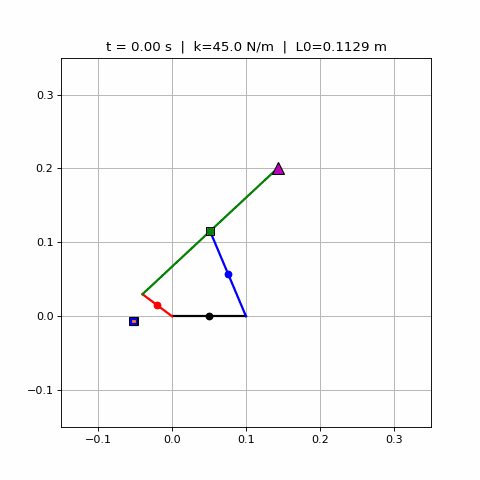

In [8]:
# =============================================================================
# CREACIÓN DEL GIF (Animación)
# =============================================================================
fig, ax = plt.subplots(figsize=(6,6))
ax.set_xlim(-0.15, 0.35)
ax.set_ylim(-0.15, 0.35)
ax.set_aspect('equal')
ax.grid(True)

# Elementos fijos (se actualizarán en cada frame)
line_b1, = ax.plot([], [], 'k-', lw=2)   # barra 1
line_b2, = ax.plot([], [], 'r-', lw=2)   # barra 2
line_b3, = ax.plot([], [], 'g-', lw=2)   # barra 3
line_b4, = ax.plot([], [], 'b-', lw=2)   # barra 4
joint_B, = ax.plot([], [], 'ks', ms=8, mfc='0.5')
cm1, = ax.plot([], [], 'ok', mfc='k', ms=6)
cm2, = ax.plot([], [], 'or', mfc='r', ms=6)
cm3, = ax.plot([], [], 'og', mfc='g', ms=6)
cm4, = ax.plot([], [], 'ob', mfc='b', ms=6)
traj_line, = ax.plot([], [], 'm-', lw=1.8)
tip_point, = ax.plot([], [], 'm^', ms=10, mfc='m', mec='k')
s2_traj, = ax.plot([], [], 'r--', lw=1.0)
s4_traj, = ax.plot([], [], 'b--', lw=1.0)
s2_point, = ax.plot([], [], 's', ms=8, mec='k', mfc='r')
s4_point, = ax.plot([], [], 's', ms=8, mec='k', mfc='b')
spring_line, = ax.plot([], [], color=[1,0.5,0], lw=2.5)
title = ax.set_title('')

def update(i):
    O2 = P[0:2, i] + Rot(P[2, i]) @ [-r1/2, 0]
    O4 = P[0:2, i] + Rot(P[2, i]) @ [ r1/2, 0]
    A  = P[3:5, i] + Rot(P[5, i]) @ [ r2/2, 0]
    B  = P[6:8, i]  # barra 4 conecta al centro de barra 3
    tip = traj_tip3[:, i]
    Ps2 = traj_s2[:, i]
    Ps4 = traj_s4[:, i]

    line_b1.set_data([O2[0], O4[0]], [O2[1], O4[1]])
    line_b2.set_data([O2[0], A[0]], [O2[1], A[1]])
    line_b3.set_data([A[0], tip[0]], [A[1], tip[1]])
    line_b4.set_data([O4[0], B[0]], [O4[1], B[1]])

    joint_B.set_data(B[0], B[1])
    cm1.set_data(P[0, i], P[1, i])
    cm2.set_data(P[3, i], P[4, i])
    cm3.set_data(P[6, i], P[7, i])
    cm4.set_data(P[9, i], P[10, i])

    # Trayectoria acumulada del extremo libre
    traj_line.set_data(traj_tip3[0, :i+1], traj_tip3[1, :i+1])
    tip_point.set_data(tip[0], tip[1])

    # Resorte
    s2_traj.set_data(traj_s2[0, :i+1], traj_s2[1, :i+1])
    s4_traj.set_data(traj_s4[0, :i+1], traj_s4[1, :i+1])
    s2_point.set_data(Ps2[0], Ps2[1])
    s4_point.set_data(Ps4[0], Ps4[1])
    spring_line.set_data([Ps2[0], Ps4[0]], [Ps2[1], Ps4[1]])

    title.set_text(f't = {time[i]:.2f} s  |  k={k} N/m  |  L0={L0:.4f} m')

    return (line_b1, line_b2, line_b3, line_b4, joint_B, cm1, cm2, cm3, cm4,
            traj_line, tip_point, s2_traj, s4_traj, s2_point, s4_point, spring_line, title)

ani = FuncAnimation(fig, update, frames=N, interval=50, blit=True)

# Guardar el GIF
gif_path = 'mecanismo.gif'
ani.save(gif_path, writer='pillow', fps=20, dpi=80)
plt.close(fig)
print(f"GIF guardado como '{gif_path}'")

# Mostrar el GIF en el notebook
display(IPImage(filename=gif_path))

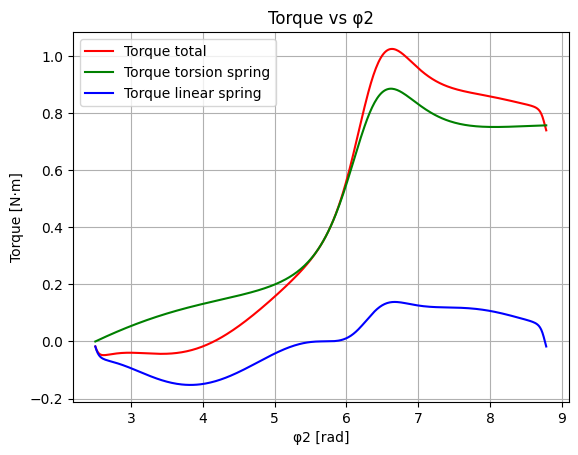

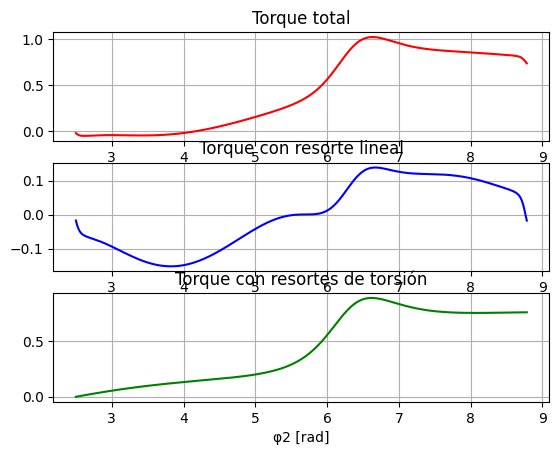

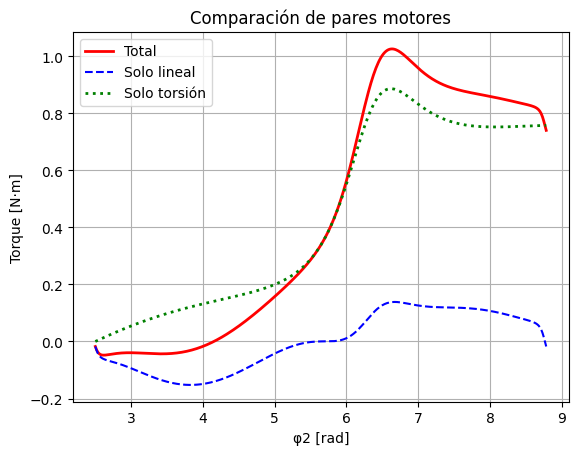

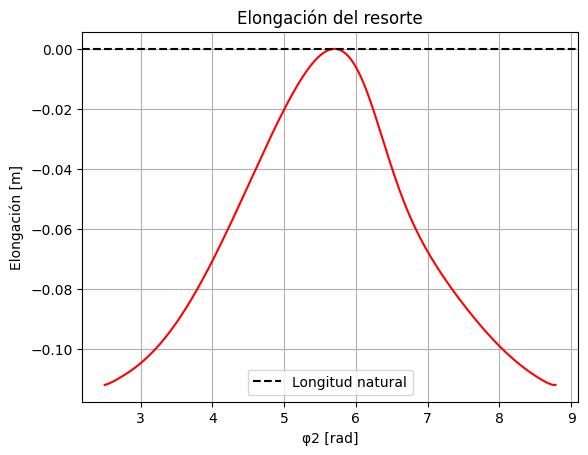

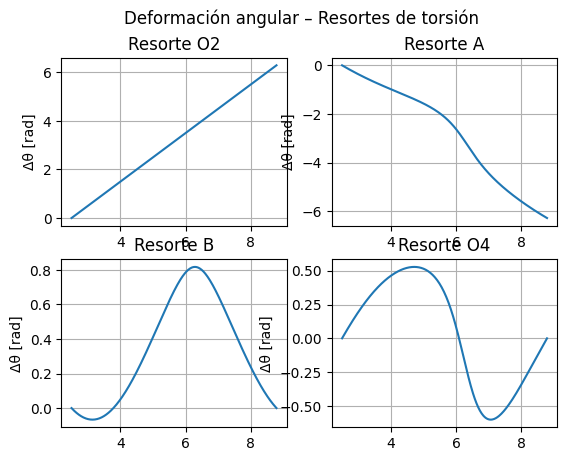

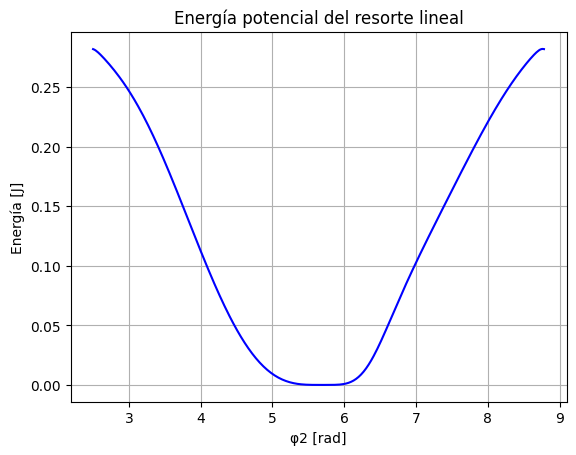

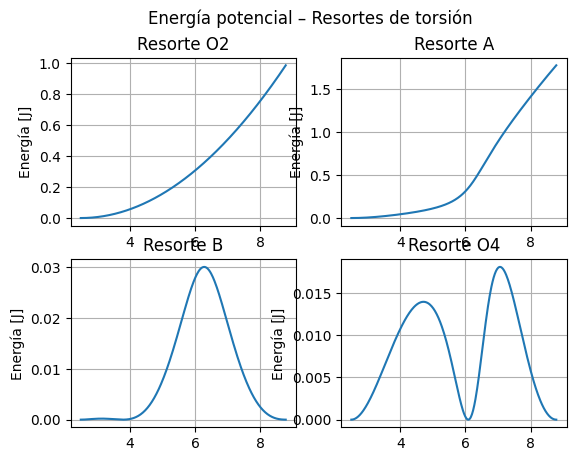

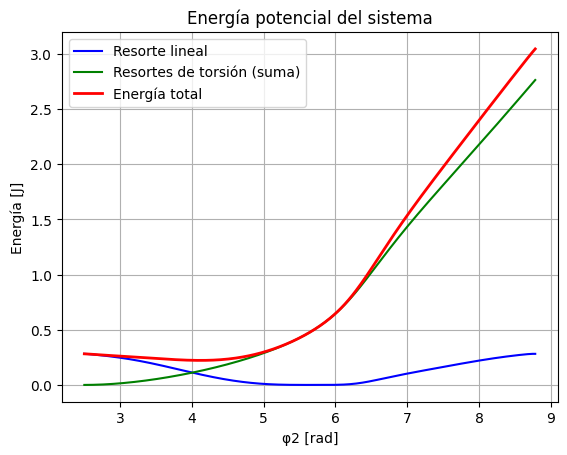

In [9]:
# ── Torque, energía, elongación ──────────────────────────────────────
# Torque comparativo (vs φ2)
plt.figure()
plt.plot(P[5, :], LBA[11, :], 'r', linewidth=1.5, label='Torque total')
plt.plot(P[5, :], Torque_torsion, 'g', linewidth=1.5, label='Torque torsion spring')
plt.plot(P[5, :], Torque_lineal, 'b', linewidth=1.5, label='Torque linear spring')
plt.grid(True)
plt.legend()
plt.xlabel('φ2 [rad]')
plt.ylabel('Torque [N·m]')
plt.title('Torque vs φ2')

# Tres subgráficas
plt.figure()
plt.subplot(3,1,1)
plt.plot(P[5, :], LBA[11, :], 'r'); plt.grid(True); plt.title('Torque total')
plt.subplot(3,1,2)
plt.plot(P[5, :], Torque_lineal, 'b'); plt.grid(True); plt.title('Torque con resorte lineal')
plt.subplot(3,1,3)
plt.plot(P[5, :], Torque_torsion, 'g'); plt.grid(True); plt.title('Torque con resortes de torsión')
plt.xlabel('φ2 [rad]')

# Comparación superpuesta
plt.figure()
plt.plot(P[5, :], LBA[11, :], 'r-', linewidth=2, label='Total')
plt.plot(P[5, :], Torque_lineal, 'b--', linewidth=1.5, label='Solo lineal')
plt.plot(P[5, :], Torque_torsion, 'g:', linewidth=2, label='Solo torsión')
plt.grid(True)
plt.legend()
plt.xlabel('φ2 [rad]')
plt.ylabel('Torque [N·m]')
plt.title('Comparación de pares motores')

# Elongación
plt.figure()
plt.plot(P[5, :], elongacion, 'r', linewidth=1.5)
plt.grid(True)
plt.axhline(0, color='k', linestyle='--', label='Longitud natural')
plt.legend()
plt.xlabel('φ2 [rad]')
plt.ylabel('Elongación [m]')
plt.title('Elongación del resorte')

# Deformaciones angulares
plt.figure()
plt.subplot(2,2,1); plt.plot(P[5, :], deform_O2); plt.grid(True); plt.title('Resorte O2'); plt.ylabel('Δθ [rad]')
plt.subplot(2,2,2); plt.plot(P[5, :], deform_A);  plt.grid(True); plt.title('Resorte A'); plt.ylabel('Δθ [rad]')
plt.subplot(2,2,3); plt.plot(P[5, :], deform_B);  plt.grid(True); plt.title('Resorte B'); plt.ylabel('Δθ [rad]')
plt.subplot(2,2,4); plt.plot(P[5, :], deform_O4); plt.grid(True); plt.title('Resorte O4'); plt.ylabel('Δθ [rad]')
plt.suptitle('Deformación angular – Resortes de torsión')

# Energías
plt.figure()
plt.plot(P[5, :], energia, 'b', linewidth=1.5)
plt.grid(True)
plt.xlabel('φ2 [rad]')
plt.ylabel('Energía [J]')
plt.title('Energía potencial del resorte lineal')

plt.figure()
plt.subplot(2,2,1); plt.plot(P[5, :], ener_O2); plt.grid(True); plt.title('Resorte O2'); plt.ylabel('Energía [J]')
plt.subplot(2,2,2); plt.plot(P[5, :], ener_A);  plt.grid(True); plt.title('Resorte A'); plt.ylabel('Energía [J]')
plt.subplot(2,2,3); plt.plot(P[5, :], ener_B);  plt.grid(True); plt.title('Resorte B'); plt.ylabel('Energía [J]')
plt.subplot(2,2,4); plt.plot(P[5, :], ener_O4); plt.grid(True); plt.title('Resorte O4'); plt.ylabel('Energía [J]')
plt.suptitle('Energía potencial – Resortes de torsión')

# Energía total del sistema
plt.figure()
plt.plot(P[5, :], energia, 'b', linewidth=1.5, label='Resorte lineal')
plt.plot(P[5, :], ener_tors_total, 'g', linewidth=1.5, label='Resortes de torsión (suma)')
plt.plot(P[5, :], energia + ener_tors_total, 'r', linewidth=2, label='Energía total')
plt.grid(True)
plt.legend(loc='best')
plt.xlabel('φ2 [rad]')
plt.ylabel('Energía [J]')
plt.title('Energía potencial del sistema')

plt.show()